# in this section , its is recommended that you go throught these links first

see here on MIT Binary Trees: https://ocw.mit.edu/courses/6-006-introduction-to-algorithms-spring-2020/resources/mit6_006s20_r06/

or more specifically, Lecture Notes Recitation 7, Lecture 7: Binary Trees, Part 2: AVL notes (PDF)
Recitation 7 notes (PDF): https://ocw.mit.edu/courses/6-006-introduction-to-algorithms-spring-2020/resources/mit6_006s20_r07/

or more generally: Introduction to Algorithms MIT free online course: https://ocw.mit.edu/courses/6-006-introduction-to-algorithms-spring-2020/pages/lecture-notes/


AVL Tree Visually Explained by ByteQuest: https://youtu.be/XeYQ2jSa2cI?si=xORum4AsKBJI9fA6

AVL Trees Simply Explained by Maaneth De Silva: https://youtu.be/zP2xbKerIds?si=wbFXWfsOILlgxxcf


or even this: AVL Trees & Rotations (Self-Balancing Binary Search Trees)
Back To Back SWE: https://youtu.be/vRwi_UcZGjU?si=8LKvDIyr6ZU9yFW1


# 🌲 AVL Tree Height Guarantee (Key Points)

The mathematical derivation below proves why an **AVL Tree** always guarantees a worst-case search time of **$O(\log n)$**.

---

### 1. The Worst-Case Node Recurrence ($N_h$)
To find the absolute *minimum* number of nodes ($N_h$) needed to build an AVL tree of height $h$, we build it as unevenly as possible (where one subtree is always $1$ level taller than the other):

$$N_h = 1 + N_{h-1} + N_{h-2}$$

* **$1$** = The root node.
* **$N_{h-1}$** = The taller subtree.
* **$N_{h-2}$** = The shorter subtree.

### 2. The Fibonacci & Golden Ratio ($\Phi$) Connection
This recurrence behaves almost exactly like the Fibonacci sequence, which can be exactly mapped as:

$$N_h = F_{h+3} - 1$$

As Fibonacci numbers grow, they closely approximate the **Golden Ratio ($\Phi \approx 1.618$)**:

$$\Phi = \frac{1 + \sqrt{5}}{2}$$

Using Binet's formula, we can approximate the growth of these numbers as:

$$F_i \approx \frac{\Phi^i}{\sqrt{5}} \implies N_h \approx \frac{\Phi^{h+3}}{\sqrt{5}} - 1$$

### 3. Logarithmic Height Derivation
If we rearrange the approximation to solve for the tree height ($h$) using base-2 logs ($\log_2$), we get:

1. **Isolate the exponential term:**  
   $$\log_2(N_h + 1) = (h + 3)\log_2(\Phi) - \frac{1}{2}\log_2(5)$$
2. **Solve for $h$:**  
   $$h = \frac{\log_2(N_h + 1) + \frac{1}{2}\log_2(5)}{\log_2(\Phi)} - 3$$

### 🎯 The Big Takeaway
When you substitute the actual value of $\Phi \approx 1.618$ into the equation, the constant factor $\frac{1}{\log_2(1.618)}$ evaluates to $\approx 1.44$. This simplifies the worst-case bound to:

$$h \le 1.44 \log_2(N_h)$$

* **Conclusion:** Even in its absolute worst/emptiest configuration, an AVL tree's height will **never** exceed $1.44 \log_2(n)$. 
* This mathematically guarantees that search, insertion, and deletion operations stay firmly at **$O(\log n)$**.


#### the BinarySearchTree



In [1]:
class TreeNode:
    def __init__(self, key, value, left=None, right=None, parent=None):
        self.key = key
        self.value = value
        self.left_child = left
        self.right_child = right
        self.parent = parent

    def is_left_child(self):
        #• Checks if this node has a parent (self.parent).
        #• Then checks if that parent's left_child points directly to self 
        #(is self checks for exact object identity in memory).
        #• Returns True if it is a left child, or False / None otherwise.
        return self.parent and self.parent.left_child is self

    def is_right_child(self):
        return self.parent and self.parent.right_child is self

    def is_root(self):
        return not self.parent

    def is_leaf(self):
        return not (self.right_child or self.left_child)

    def has_any_child(self):
        return self.right_child or self.left_child

    def has_children(self):
        return self.right_child and self.left_child

    def replace_value(self, key, value, left, right):
        #Updating the Current Node's Properties
        self.key = key
        self.value = value
        self.left_child = left
        self.right_child = right
        if self.left_child: #if self.left_child:: This checks if a left child actually exists (meaning the left argument passed in wasn't None).
             #If the left child exists, this line tells that child, "Hey, I am your new parent now."   
            self.left_child.parent = self
        if self.right_child:
            self.right_child.parent = self

    def find_successor(self):
        successor = None
        if self.right_child: 
            #Case1: If the node has a right child, then the successor is the smallest key in the right subtree
            successor = self.right_child.find_min()
        else:
            if self.parent: 
                #Case2: If the node has no right child and is the left child of its parent, then the parent is the successor
                if self.is_left_child():# if it is a left child?
                    successor = self.parent
                else: # may be its the right child 
                    #If the node is the right child of its parent,
                    #and itself has no right child, then the successor to this node is the successor of its parent,
                    #excluding this node.
                    self.parent.right_child = None
                    successor = self.parent.find_successor()
                    self.parent.right_child = self
        return successor

    def find_min(self):
        current = self
        while current.left_child:
            current = current.left_child
        return current

    def splice_out(self):# this like delete? used in delete funstion in: class BinarySearchTree 
        if self.is_leaf():
            if self.is_left_child():
                self.parent.left_child = None
            else:
                self.parent.right_child = None
        elif self.has_any_child():
            if self.left_child:
                if self.is_left_child():
                    self.parent.left_child = self.left_child
                else:
                    self.parent.right_child = self.left_child
                self.left_child.parent = self.parent # else its the root
            else:
                if self.is_left_child():
                    self.parent.left_child = self.right_child
                else:
                    self.parent.right_child = self.right_child
                self.right_child.parent = self.parent

    def __iter__(self): #lets Enable Loops
        if self:
            if self.left_child:
                #for elem in self.left_child:: This is a recursive loop.
                #Because self.left_child is also a TreeNode,
                #looping over it automatically triggers its __iter__ method.
                #It dives all the way down to the leftmost leaf node first.
                #yield elem: Forwards every key found in the left subtree up to the main loop.
                #It dives all the way down to the leftmost leaf node first.
                for elem in self.left_child:
                    yield elem
            yield self.key #Yielding the Current Node
            if self.right_child:
                for elem in self.right_child:
                    yield elem


class BinarySearchTree:
    def __init__(self):
        self.root = None
        self.size = 0

    def __len__(self):
        return self.size

    def __iter__(self):
        return self.root.__iter__()

    def put(self, key, value):
        if self.root:
            self._put(key, value, self.root)
        else:
            self.root = TreeNode(key, value)
        self.size = self.size + 1

#Starting at the root of the tree, search the binary tree comparing the new key to the key in the current node.
#If the new key is less than the current node, search the left subtree.
#If the new key is greater than the current node, search the right subtree.
#When there is no left or right child to search, we have found the position in the tree where the new node should be installed.
#To add a node to the tree, create a new TreeNode object and insert the object at the point discovered in the previous step.                    
    def _put(self, key, value, current_node):
        if key < current_node.key:
            if current_node.left_child:
                self._put(key, value, current_node.left_child)
            else:
                current_node.left_child = TreeNode(
                    key, value, parent=current_node
                )
        else:
            if current_node.right_child:
                self._put(key, value, current_node.right_child)
            else:
                current_node.right_child = TreeNode(
                    key, value, parent=current_node
                )


    def __setitem__(self, key, value):
        #This allows us to write Python statements like my_zip_tree['Plymouth'] = 55446, just like a Python dictionary.
        self.put(key, value)

    def get(self, key):
        if self.root:
            result = self._get(key, self.root)
            if result:
                return result.value
        return None

    def _get(self, key, current_node):
        if not current_node:
            return None
        if current_node.key == key:
            return current_node
        elif key < current_node.key:
            return self._get(key, current_node.left_child)
        else:
            return self._get(key, current_node.right_child)

    def __getitem__(self, key):
        return self.get(key)

    def __contains__(self, key):
        #Recall that __contains__ overloads the in operator and allows us to write statements such as
        #"Northfield" in my_zip_tree.
        return bool(self._get(key, self.root))

    def delete(self, key):
        if self.size > 1:
            node_to_remove = self._get(key, self.root)
            if node_to_remove:
                self._delete(node_to_remove)
                self.size = self.size - 1
            else:
                raise KeyError("Error, key not in tree")
        elif self.size == 1 and self.root.key == key:
            self.root = None
            self.size = self.size - 1
        else:
            raise KeyError("Error, key not in tree")

    def _delete(self, current_node):
        if current_node.is_leaf():  # Case1: removing a leaf
            if current_node == current_node.parent.left_child:
                current_node.parent.left_child = None
            else:
                current_node.parent.right_child = None
        elif current_node.has_children():  #Case2: removing a node with two children
            successor = current_node.find_successor()
            successor.splice_out() #is this the actual deletion? is it swapping?
            current_node.key = successor.key
            current_node.value = successor.value
        else:  #Case3: removing a node with one child,we simply promote the child to take the place of its parent.
            if current_node.left_child:
                if current_node.is_left_child():
                    current_node.left_child.parent = current_node.parent
                    current_node.parent.left_child = current_node.left_child
                elif current_node.is_right_child():
                    current_node.left_child.parent = current_node.parent
                    current_node.parent.right_child = current_node.left_child
                else: 
                    #If the current node has no parent, it must be the root.
                    #the function replace_value is described on the: class TreeNode
                    # In this case we will just replace the key, value, left_child, and right_child data
                    #by calling the replace_value method on the root.
                     #It leaves the root node object right where it is in memory,
                    #but overwrites its contents with the contents of its only child.
                    current_node.replace_value(
                        current_node.left_child.key, #get the key of left child
                        current_node.left_child.value, #get value of the right child
                        current_node.left_child.left_child,
                        current_node.left_child.right_child,
                    )
            else:
                if current_node.is_left_child():
                    current_node.right_child.parent = current_node.parent
                    current_node.parent.left_child = current_node.right_child
                elif current_node.is_right_child():
                    current_node.right_child.parent = current_node.parent
                    current_node.parent.right_child = current_node.right_child
                else:
                    current_node.replace_value(
                        current_node.right_child.key,
                        current_node.right_child.value,
                        current_node.right_child.left_child,
                        current_node.right_child.right_child,
                    )

    def __delitem__(self, key):
        #It is a wrapper method that allows us to remove a key from the map by writing del my_zip_tree["NYC"].
        self.delete(key)


my_tree = BinarySearchTree()
my_tree["a"] = "a"
my_tree["q"] = "quick"
my_tree["b"] = "brown"
my_tree["f"] = "fox"
my_tree["j"] = "jumps"
my_tree["o"] = "over"
my_tree["t"] = "the"
my_tree["l"] = "lazy"
my_tree["d"] = "dog"

print(my_tree["q"])
print(my_tree["l"])
print("There are {} items in this tree".format(len(my_tree)))
my_tree.delete("a")
print("There are {} items in this tree".format(len(my_tree)))

for node in my_tree:
    print(my_tree[node], end=" ")
print()


quick
lazy
There are 9 items in this tree
There are 8 items in this tree
brown dog fox jumps lazy over quick the 


#### We will implement the AVL tree as a subclass of BinarySearchTree

In [8]:
class AVLTree(BinarySearchTree):
    """The subclass that inherits from BinarySearchTree and adds balancing."""

    def __init__(self):
        # Initialize the parent BST class properties
        super().__init__()

    def _put(self, key, value, current_node):
        if key < current_node.key:
            if current_node.left_child:
                self._put(key, value, current_node.left_child)
            else:
                current_node.left_child = AVLTreeNode(
                    key, value, 0, parent=current_node
                )
                self.update_balance(current_node.left_child)
        else:
            if current_node.right_child:
                self._put(key, value, current_node.right_child)
            else:
                current_node.right_child = AVLTreeNode(
                    key, value, 0, parent=current_node
                )
                self.update_balance(current_node.right_child)
    
    def update_balance(self, node):
        if node.balance_factor > 1 or node.balance_factor < -1:
            self.rebalance(node)
            return
        if node.parent:
            if node.is_left_child():
                node.parent.balance_factor += 1
            elif node.is_right_child():
                node.parent.balance_factor -= 1
    
            if node.parent.balance_factor != 0:
                self.update_balance(node.parent)


    def rotate_right(self, rotation_root):
        # 1. Pivot around the left child
        new_root = rotation_root.left_child # Promote the left child (C) to be the root of the subtree.
        rotation_root.left_child = new_root.right_child
    
        # 2. Update the moving child's parent reference
        if new_root.right_child:
            new_root.right_child.parent = rotation_root 
    
        # 3. Connect new_root to the rest of the tree above
        new_root.parent = rotation_root.parent
        if rotation_root.is_root():
            self._root = new_root
        else:
            if rotation_root.is_left_child():
                rotation_root.parent.left_child = new_root
            else:
                rotation_root.parent.right_child = new_root
    
        # 4. Finish the pivot adjustments
        new_root.right_child = rotation_root
        rotation_root.parent = new_root
    
        # 5. Mirror the balance factor updates
        rotation_root.balance_factor = (
            rotation_root.balance_factor - 1 - max(new_root.balance_factor, 0)
        )
        new_root.balance_factor = (
            new_root.balance_factor - 1 + min(rotation_root.balance_factor, 0)
        )

    def rotate_left(self, rotation_root):
        # 1. Track the node that will move up to become the new root of this subtree
        new_root = rotation_root.right_child
    
        # 2. Give the old root the left child of the new root as its new right child
        rotation_root.right_child = new_root.left_child
    
        # 3. If that shifting child exists, update its upward parent pointer to the old root
        if new_root.left_child:
            new_root.left_child.parent = rotation_root
    
        # 4. Connect the new root upward to the grandparent node above it
        new_root.parent = rotation_root.parent
    
        # 5. Connect the grandparent node downward to the new root
        if rotation_root.is_root():
            # If the old root was the ultimate tree root, update the tree manager pointer
            self._root = new_root
        else:
            # If the old root was a left child, update the grandparent's left slot
            if rotation_root.is_left_child():
                rotation_root.parent.left_child = new_root
            # Otherwise, update the grandparent's right slot
            else:
                rotation_root.parent.right_child = new_root
    
        # 6. Complete the pivot: make the old root the left child of the new root
        new_root.left_child = rotation_root
    
        # 7. Update the old root's parent pointer to point up to the new root
        rotation_root.parent = new_root
    
        # 8. Recompute the balance factors for only the two affected nodes
        rotation_root.balance_factor = (
            rotation_root.balance_factor + 1 - min(new_root.balance_factor, 0)
        )
        new_root.balance_factor = (
            new_root.balance_factor + 1 + max(rotation_root.balance_factor, 0)
        )


    def rebalance(self, node):
        # Rule 1: The node is right-heavy (needs a left rotation)
        if node.balance_factor < 0:
            # Check if the right child is left-heavy (a "zig-zag" pattern)
            if node.right_child.balance_factor > 0:
                # Fix the zig-zag by right-rotating the child first
                self.rotate_right(node.right_child)
                # Perform the original left rotation to complete the balance
                self.rotate_left(node)
            else:
                # The right child is also right-heavy; a single left rotation is enough
                self.rotate_left(node)
    
        # Rule 2: The node is left-heavy (needs a right rotation)
        elif node.balance_factor > 0:
            # Check if the left child is right-heavy (a "zag-zig" pattern)
            if node.left_child.balance_factor < 0:
                # Fix the zag-zig by left-rotating the child first
                self.rotate_left(node.left_child)
                # Perform the original right rotation to complete the balance
                self.rotate_right(node)
            else:
                # The left child is also left-heavy; a single right rotation is enough
                self.rotate_right(node)
    
            


#### pay ground

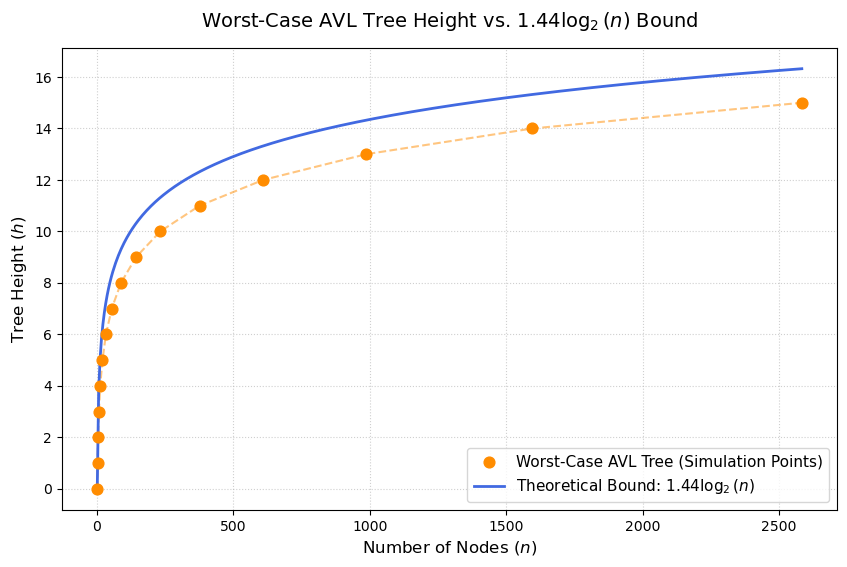

In [2]:
#code from AI

import matplotlib.pyplot as plt
import numpy as np

# 1. Simulate the minimal AVL tree sizes using the recurrence relation
# N_h = 1 + N_{h-1} + N_{h-2}
heights = [0, 1]
nodes = [1, 2]  # N_0 = 1, N_1 = 2

# Generate data up to height 15 to show the trend clearly
for h in range(2, 16):
    heights.append(h)
    nodes.append(1 + nodes[h - 1] + nodes[h - 2])

# Convert to numpy arrays for calculation
nodes = np.array(nodes)
heights = np.array(heights)

# 2. Calculate the theoretical upper bound curve: 1.44 * log2(N)
# We use a smooth range of N values for a pretty curve
nodes_smooth = np.linspace(1, max(nodes), 500)
theoretical_bound = 1.44 * np.log2(nodes_smooth)

# 3. Plot the results
plt.figure(figsize=(10, 6))

# Plot the real simulation points
plt.scatter(
    nodes,
    heights,
    color="darkorange",
    s=60,
    zorder=3,
    label="Worst-Case AVL Tree (Simulation Points)",
)
plt.plot(
    nodes,
    heights,
    color="darkorange",
    linestyle="--",
    alpha=0.5,
)

# Plot the 1.44 * log2(n) mathematical limit line
plt.plot(
    nodes_smooth,
    theoretical_bound,
    color="royalblue",
    linewidth=2,
    label="Theoretical Bound: $1.44 \log_2(n)$",
)

# Formatting the chart
plt.title(
    "Worst-Case AVL Tree Height vs. $1.44 \log_2(n)$ Bound",
    fontsize=14,
    pad=15,
)
plt.xlabel("Number of Nodes ($n$)", fontsize=12)
plt.ylabel("Tree Height ($h$)", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(fontsize=11, loc="lower right")

# Show the plot inside Jupyter
plt.show()


In [8]:
#code block from AI
class AVLTreeNode:

    def __init__(self, key, value):
        self.key = key
        self.value = value
        self.left = None
        self.right = None
        self.height = 1  # New nodes start with a height of 1


class AVLTree:

    def __init__(self):
        self.root = None

    def get_height(self, node):
        """Helper to get node height safely (handles None nodes)."""
        return node.height if node else 0

    def get_balance(self, node):
        """Calculates the balance factor of a node."""
        if not node:
            return 0
        return self.get_height(node.left) - self.get_height(node.right)

    def right_rotate(self, y):
        """Performs a right rotation to balance a left-heavy subtree."""
        x = y.left
        T2 = x.right

        # Perform rotation
        x.right = y
        y.left = T2

        # Update heights
        y.height = max(self.get_height(y.left), self.get_height(y.right)) + 1
        x.height = max(self.get_height(x.left), self.get_height(x.right)) + 1

        # Return new root of this subtree
        return x

    def left_rotate(self, x):
        """Performs a left rotation to balance a right-heavy subtree."""
        y = x.right
        T2 = y.left

        # Perform rotation
        y.left = x
        x.right = T2

        # Update heights
        x.height = max(self.get_height(x.left), self.get_height(x.right)) + 1
        y.height = max(self.get_height(y.left), self.get_height(y.right)) + 1

        # Return new root of this subtree
        return y

    def insert(self, key, value):
        """Public insertion entry point."""
        self.root = self._insert(self.root, key, value)

    def _insert(self, node, key, value):
        """Recursive helper to insert a node and rebalance up the path."""
        # 1. Standard BST insertion
        if not node:
            return AVLTreeNode(key, value)

        if key < node.key:
            node.left = self._insert(node.left, key, value)
        elif key > node.key:
            node.right = self._insert(node.right, key, value)
        else:
            node.value = value  # Update value if key already exists
            return node

        # 2. Update height of the current ancestor node
        node.height = (
            max(self.get_height(node.left), self.get_height(node.right)) + 1
        )

        # 3. Get the balance factor to check if it became unbalanced
        balance = self.get_balance(node)

        # 4. If unbalanced, handle the 4 structural scenarios:

        # Case 1: Left Left (Single Right Rotation)
        if balance > 1 and key < node.left.key:
            return self.right_rotate(node)

        # Case 2: Right Right (Single Left Rotation)
        if balance < -1 and key > node.right.key:
            return self.left_rotate(node)

        # Case 3: Left Right (Double Rotation: Left then Right)
        if balance > 1 and key > node.left.key:
            node.left = self.left_rotate(node.left)
            return self.right_rotate(node)

        # Case 4: Right Left (Double Rotation: Right then Left)
        if balance < -1 and key < node.right.key:
            node.right = self.right_rotate(node.right)
            return self.left_rotate(node)

        return node

    def in_order_traversal(self):
        """Public helper to get sorted keys."""
        keys = []
        self._in_order(self.root, keys)
        return keys

    def _in_order(self, node, keys):
        if node:
            self._in_order(node.left, keys)
            keys.append(node.key)
            self._in_order(node.right, keys)



# --- Quick Execution Test ---
tree = AVLTree()

# Using a range function to bypass the bracket rendering glitch!
# This generates: 10, 20, 30, 40, 50
dataset = list(range(10, 60, 10))

for num in dataset:
    tree.insert(num, f"Data-{num}")

print("Root after self-balancing rotations:", tree.root.key)  # Expected: 30
print("Overall tree height:", tree.get_height(tree.root))       # Expected: 3 (Balanced depth)
print("Sorted keys via in-order traversal:", tree.in_order_traversal())


Root after self-balancing rotations: 20
Overall tree height: 3
Sorted keys via in-order traversal: [10, 20, 30, 40, 50]
